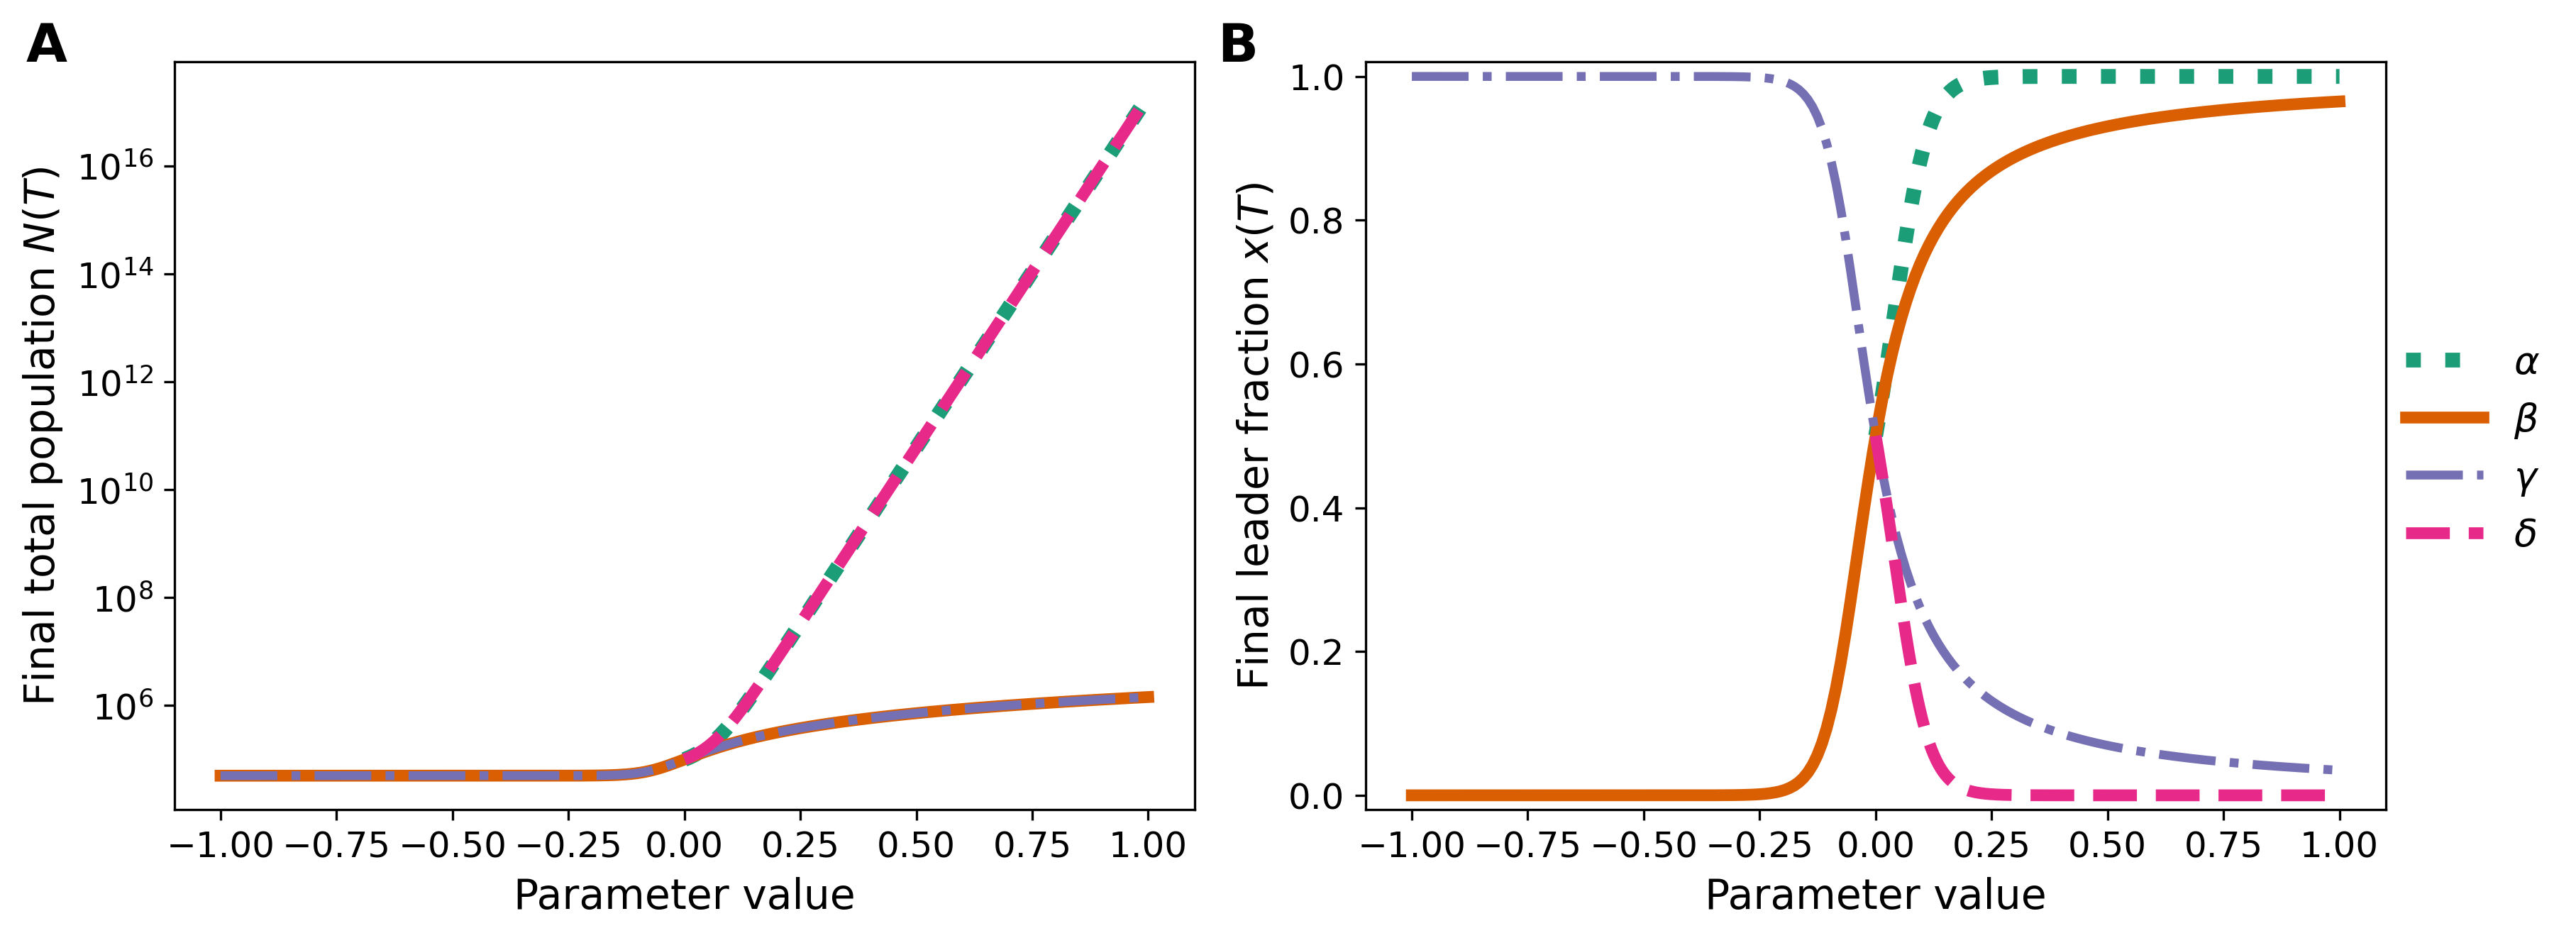

Saved: one_at_a_time_from_zero.pdf


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

# ============================================================
# Replicator model with intrinsic + cross-interaction terms
# f_L = alpha*x + beta*(1-x)
# f_F = gamma*x + delta*(1-x)
# ============================================================

def f_L(x, params):
    alpha = params["alpha"]
    beta  = params["beta"]
    return alpha*x + beta*(1.0 - x)

def f_F(x, params):
    gamma = params["gamma"]
    delta = params["delta"]
    return gamma*x + delta*(1.0 - x)

def rhs(y, t, params):
    N, x = y
    x = float(np.clip(x, 1e-12, 1.0 - 1e-12))

    fL = f_L(x, params)
    fF = f_F(x, params)

    dN = ((fL - fF) * N * x + fF * N)     # = N*(x*fL + (1-x)*fF)
    dx = (fL - fF) * x * (1.0 - x)
    return [dN, dx]

def simulate_final(params, t, N0, x0):
    x0_use = np.clip(float(x0), 1e-12, 1.0 - 1e-12)

    sol = odeint(rhs, [float(N0), x0_use], t, args=(params,), mxstep=2000)

    N_end = float(sol[-1, 0])
    x_end = float(sol[-1, 1])

    N_end = max(N_end, 0.0)
    x_end = float(np.clip(x_end, 0.0, 1.0))

    if float(x0) == 0.0:
        x_end = 0.0
    if float(x0) == 1.0:
        x_end = 1.0

    return N_end, x_end

# ============================================================
# One-at-a-time sweep from baseline zeros
# ============================================================

def one_at_a_time_sweep(
    N0=1e5, x0=0.5,
    T=30, nt=1500,
    alpha_vals=np.linspace(0, 1.0, 200),
    delta_vals=np.linspace(0, 1.0, 200),
    beta_vals=np.linspace(-1.0, 1.0, 200),
    gamma_vals=np.linspace(-1.0, 1.0, 200),
    savepath="one_at_a_time_from_zero.pdf"
):
    t = np.linspace(0, T, nt)

    baseline = {"alpha": 0.0, "beta": 0.0, "gamma": 0.0, "delta": 0.0}

    # (key, label, grid, color, linestyle, linewidth)
    sweeps = [
        ("alpha", r"$\alpha$", alpha_vals, "#1B9E77", ":",  5),   # teal
        ("beta",  r"$\beta$",  beta_vals,  "#D95F02", "-",  4),   # burnt orange
        ("gamma", r"$\gamma$", gamma_vals, "#7570B3", "-.", 3),   # muted purple
        ("delta", r"$\delta$", delta_vals, "#E7298A", "--", 4),   # magenta
    ]

    results = {}
    for key, label, grid, color, ls, lw in sweeps:   # ✅ correct unpacking
        N_end_list = []
        x_end_list = []

        grid = np.asarray(grid, dtype=float)

        for v in grid:
            p = baseline.copy()
            p[key] = float(v)
            N_end, x_end = simulate_final(p, t, N0, x0)
            N_end_list.append(N_end)
            x_end_list.append(x_end)

        results[key] = {
            "label": label,
            "grid": grid,
            "color": color,
            "ls": ls,
            "lw": lw,
            "N_end": np.asarray(N_end_list, dtype=float),
            "x_end": np.asarray(x_end_list, dtype=float)
        }

    # ========================================================
    # Plot
    # ========================================================
    plt.rcParams.update({
        "font.size": 13,
        "axes.titlesize": 13,
        "axes.labelsize": 14,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })

    fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.6), dpi=300)
    axN, axX = axs

    order = ["alpha", "beta", "gamma", "delta"]

    # Panel A: N(T)
    for key in order:
        r = results[key]
        axN.plot(r["grid"], r["N_end"], lw=r["lw"], color=r["color"], ls=r["ls"], label=r["label"])
    axN.set_yscale("log")
    axN.set_xlabel("Parameter value")
    axN.set_ylabel(r"Final total population $N(T)$")
    axN.grid(False)
    axN.text(-0.145, 1.055, "A", transform=axN.transAxes,
             fontsize=18, fontweight="bold", va="top")

    # Panel B: x(T)
    for key in order:
        r = results[key]
        axX.plot(r["grid"], r["x_end"], lw=r["lw"], color=r["color"], ls=r["ls"], label=r["label"])
    axX.set_ylim(-0.02, 1.02)
    axX.set_xlabel("Parameter value")
    axX.set_ylabel(r"Final leader fraction $x(T)$")
    axX.grid(False)
    axX.text(-0.145, 1.055, "B", transform=axX.transAxes,
             fontsize=18, fontweight="bold", va="top")

    # Single legend for both panels
    handles, labels = axX.get_legend_handles_labels()
    fig.legend(handles, labels, loc="center right", bbox_to_anchor=(1.06, 0.52),
               frameon=False, fontsize=13)

    plt.tight_layout()
    fig.savefig(savepath, bbox_inches="tight")
    plt.show()
    print(f"Saved: {savepath}")

# ============================================================
# RUN
# ============================================================
if __name__ == "__main__":
    one_at_a_time_sweep(savepath="one_at_a_time_from_zero.pdf")